# Análisis de eficiencia operativa y detección de operadores ineficaces

### Proyecto de Data Analytics — Servicio de telefonía virtual

## Objetivo

Analizar el desempeño de los operadores de un servicio de telefonía virtual para identificar posibles problemas operativos relacionados con las llamadas perdidas, los tiempos de espera y la actividad de llamadas salientes.

El propósito es construir indicadores de desempeño, detectar operadores que requieren atención y proponer acciones que ayuden a mejorar la calidad del servicio.

## Herramientas utilizadas

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- SciPy
- Jupyter Notebook

## Metodología

1. Exploración y evaluación de calidad de los datos.
2. Preparación y limpieza de los registros.
3. Análisis exploratorio del comportamiento de las llamadas.
4. Construcción de indicadores operativos (KPIs).
5. Identificación y segmentación de operadores mediante reglas de desempeño.
6. Evaluación estadística e interpretación de resultados.
7. Recomendaciones para la mejora operativa.

## 1. Importación y revisión inicial de datos

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df_dataset = pd.read_csv('telecom_dataset_new.csv')
df_clients = pd.read_csv('telecom_clients.csv')

display(df_dataset.info())
print()
display(df_dataset.head(10))
print()
display(df_clients.info())
print()
display(df_clients.head(10))

<class 'pandas.DataFrame'>
RangeIndex: 53902 entries, 0 to 53901
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   user_id              53902 non-null  int64  
 1   date                 53902 non-null  str    
 2   direction            53902 non-null  str    
 3   internal             53785 non-null  object 
 4   operator_id          45730 non-null  float64
 5   is_missed_call       53902 non-null  bool   
 6   calls_count          53902 non-null  int64  
 7   call_duration        53902 non-null  int64  
 8   total_call_duration  53902 non-null  int64  
dtypes: bool(1), float64(1), int64(4), object(1), str(2)
memory usage: 2.7+ MB


None

,user_id,date,direction,internal,operator_id,is_missed_call,calls_count,call_duration,total_call_duration
0,166377,2019-08-04 00:00:00+03:00,in,False,NaN,True,2,0,4
1,166377,2019-08-05 00:00:00+03:00,out,True,880022.0,True,3,0,5
2,166377,2019-08-05 00:00:00+03:00,out,True,880020.0,True,1,0,1
3,166377,2019-08-05 00:00:00+03:00,out,True,880020.0,False,1,10,18
4,166377,2019-08-05 00:00:00+03:00,out,False,880022.0,True,3,0,25
5,166377,2019-08-05 00:00:00+03:00,out,False,880020.0,False,2,3,29
6,166377,2019-08-05 00:00:00+03:00,out,False,880020.0,True,8,0,50
7,166377,2019-08-05 00:00:00+03:00,in,False,NaN,True,6,0,35
8,166377,2019-08-05 00:00:00+03:00,out,False,880020.0,True,8,0,50
9,166377,2019-08-06 00:00:00+03:00,in,False,NaN,True,4,0,62



<class 'pandas.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   user_id      732 non-null    int64
 1   tariff_plan  732 non-null    str  
 2   date_start   732 non-null    str  
dtypes: int64(1), str(2)
memory usage: 11.5 KB


None

,user_id,tariff_plan,date_start
0,166713,A,2019-08-15
1,166901,A,2019-08-23
2,168527,A,2019-10-29
3,167097,A,2019-09-01
4,168193,A,2019-10-16
5,167764,A,2019-09-30
6,167050,A,2019-08-29
7,168252,A,2019-10-17
8,168495,A,2019-10-28
9,167879,A,2019-10-03


Se cargan los datasets proporcionados, se convierten en DataFrames y se imprime la información para validar los datos.

## 2. Preparación y limpieza de datos

In [4]:
df_dataset.columns = df_dataset.columns.str.strip()
df_clients.columns = df_clients.columns.str.strip()

display('VALORES AUSENTES (df_dataset)')
print()
display(df_dataset.isnull().sum())
print()
display('VALORES DUPLICADOS (df_dataset)')
print()
print(df_dataset.duplicated().sum())
print()

display('VALORES AUSENTES (df_clients)')
print()
display(df_clients.isnull().sum())
print()
display('VALORES DUPLICADOS (df_clients)')
print()
print(df_clients.duplicated().sum())

'VALORES AUSENTES (df_dataset)'

user_id                   0
date                      0
direction                 0
internal                117
operator_id            8172
is_missed_call            0
calls_count               0
call_duration             0
total_call_duration       0
dtype: int64

'VALORES DUPLICADOS (df_dataset)'


4900



'VALORES AUSENTES (df_clients)'

user_id        0
tariff_plan    0
date_start     0
dtype: int64

'VALORES DUPLICADOS (df_clients)'


0


In [5]:
df_dataset['date'] = pd.to_datetime(df_dataset['date'])
df_clients['date_start'] = pd.to_datetime(df_clients['date_start'])

registros_antes = len(df_dataset)

df_dataset = (
    df_dataset
    .drop_duplicates()
    .reset_index(drop=True)
)

print(f"Registros originales: {registros_antes:,}")
print(f"Registros tras eliminar duplicados: {len(df_dataset):,}")

df_operadores = df_dataset.dropna(
    subset=['operator_id']
).copy()

df_operadores['operator_id'] = (
    df_operadores['operator_id'].astype('int64')
)

print(f"Registros con operador asignado: {len(df_operadores):,}")
print(f"Registros sin operador asignado: {df_dataset['operator_id'].isna().sum():,}")

display(df_dataset.info())
display(df_operadores.head())
display(df_clients.head())

Registros originales: 53,902
Registros tras eliminar duplicados: 49,002
Registros con operador asignado: 41,546
Registros sin operador asignado: 7,456
<class 'pandas.DataFrame'>
RangeIndex: 49002 entries, 0 to 49001
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype                    
---  ------               --------------  -----                    
 0   user_id              49002 non-null  int64                    
 1   date                 49002 non-null  datetime64[us, UTC+03:00]
 2   direction            49002 non-null  str                      
 3   internal             48892 non-null  object                   
 4   operator_id          41546 non-null  float64                  
 5   is_missed_call       49002 non-null  bool                     
 6   calls_count          49002 non-null  int64                    
 7   call_duration        49002 non-null  int64                    
 8   total_call_duration  49002 non-null  int64                    
dtyp

None

,user_id,date,direction,internal,operator_id,is_missed_call,calls_count,call_duration,total_call_duration
1,166377,2019-08-05 00:00:00+03:00,out,True,880022,True,3,0,5
2,166377,2019-08-05 00:00:00+03:00,out,True,880020,True,1,0,1
3,166377,2019-08-05 00:00:00+03:00,out,True,880020,False,1,10,18
4,166377,2019-08-05 00:00:00+03:00,out,False,880022,True,3,0,25
5,166377,2019-08-05 00:00:00+03:00,out,False,880020,False,2,3,29


,user_id,tariff_plan,date_start
0,166713,A,2019-08-15
1,166901,A,2019-08-23
2,168527,A,2019-10-29
3,167097,A,2019-09-01
4,168193,A,2019-10-16


### Preparación de datos

Se revisaron los valores ausentes y los registros duplicados de las dos fuentes de información.

Para conservar la mayor cantidad de información posible, se mantienen dos conjuntos de datos:

- `df_dataset`: registros de llamadas disponibles después de eliminar duplicados exactos, utilizados para analizar el tráfico general.
- `df_operadores`: subconjunto de registros con operador identificado, utilizado para calcular indicadores individuales de desempeño.

Esta separación permite analizar el comportamiento general del servicio sin descartar automáticamente las llamadas que no tienen un operador asociado.

Las columnas de fecha se convirtieron al tipo `datetime` para facilitar su análisis temporal.


## 3. Análisis exploratorio de datos (EDA)

In [6]:
display('ESTADISTICAS DEL TRAFICO')
print()
display(df_dataset[['calls_count', 'call_duration', 'total_call_duration']].describe())
print()

display('PROPORCION DE LLAMADAS POR DIRECCION')
print()
display(df_dataset['direction'].value_counts(normalize=True) * 100)

'ESTADISTICAS DEL TRAFICO'

,calls_count,call_duration,total_call_duration
count,49002.000000,49002.000000,49002.000000
mean,16.462777,866.282091,1156.558202
std,63.604098,3775.503352,4451.473661
min,1.000000,0.000000,0.000000
25%,1.000000,0.000000,46.000000
50%,4.000000,37.000000,208.000000
75%,12.000000,570.000000,901.000000
max,4817.000000,144395.000000,166155.000000


'PROPORCION DE LLAMADAS POR DIRECCION'

direction
out    59.179217
in     40.820783
Name: proportion, dtype: float64

In [7]:
print("DISTRIBUCIÓN DE LLAMADAS INTERNAS Y EXTERNAS")

distribucion_interna = (
    df_dataset
    .groupby('internal', dropna=False)['calls_count']
    .sum()
)

display(
    (distribucion_interna / distribucion_interna.sum() * 100)
    .round(2)
)

print("\nTASA DE LLAMADAS PERDIDAS POR DIRECCIÓN")

llamadas_por_direccion = (
    df_dataset
    .groupby(['direction', 'is_missed_call'])['calls_count']
    .sum()
    .unstack(fill_value=0)
)

tasas_por_direccion = (
    llamadas_por_direccion
    .div(llamadas_por_direccion.sum(axis=1), axis=0)
    * 100
)

display(llamadas_por_direccion)
display(tasas_por_direccion.round(2))

DISTRIBUCIÓN DE LLAMADAS INTERNAS Y EXTERNAS


internal
False    98.16
True      1.82
NaN       0.03
Name: calls_count, dtype: float64


TASA DE LLAMADAS PERDIDAS POR DIRECCIÓN


is_missed_call,False,True
direction,,
in,93522,104323
out,337269,271595


is_missed_call,False,True
direction,,
in,47.27,52.73
out,55.39,44.61


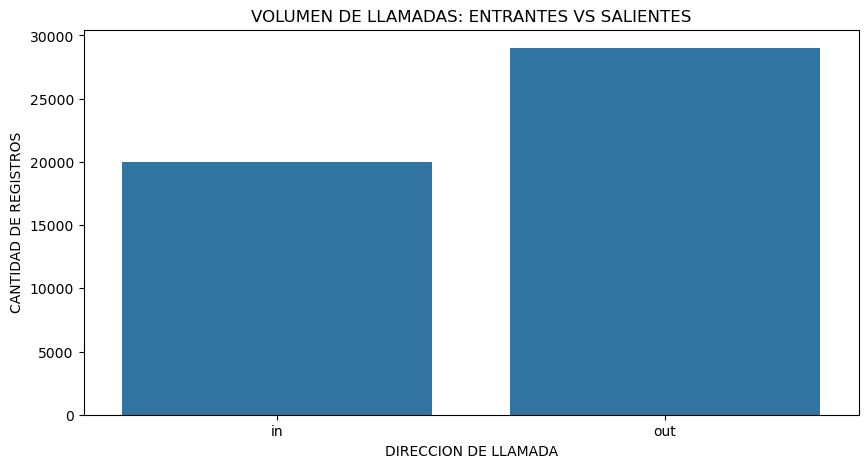

In [8]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df_dataset, x='direction')
plt.title('VOLUMEN DE LLAMADAS: ENTRANTES VS SALIENTES')
plt.xlabel('DIRECCION DE LLAMADA')
plt.ylabel('CANTIDAD DE REGISTROS')
plt.show()

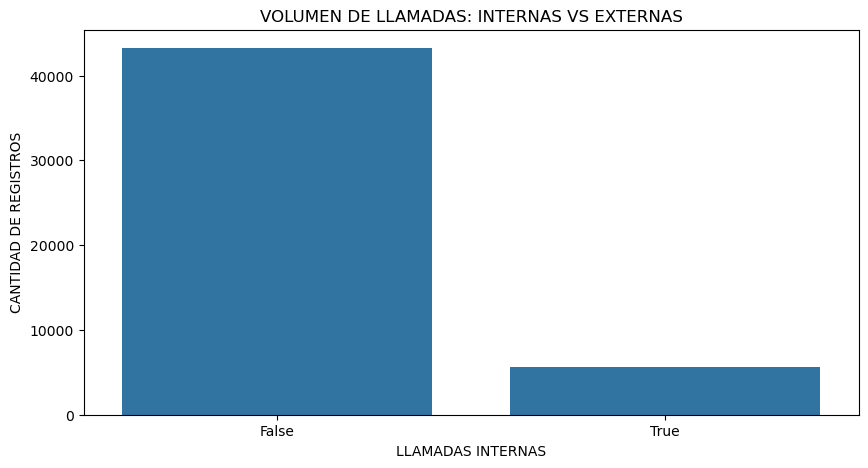

In [9]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df_dataset, x='internal')
plt.title('VOLUMEN DE LLAMADAS: INTERNAS VS EXTERNAS')
plt.xlabel('LLAMADAS INTERNAS')
plt.ylabel('CANTIDAD DE REGISTROS')
plt.show()

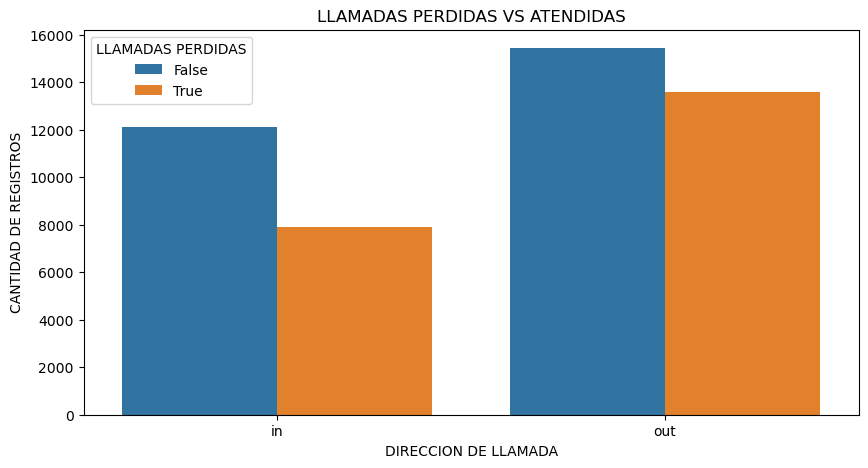

In [10]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df_dataset, x='direction', hue='is_missed_call')
plt.title('LLAMADAS PERDIDAS VS ATENDIDAS')
plt.xlabel('DIRECCION DE LLAMADA')
plt.ylabel('CANTIDAD DE REGISTROS')
plt.legend(title='LLAMADAS PERDIDAS')
plt.show()

### Interpretación del análisis exploratorio

El análisis permite distinguir el tráfico de llamadas entrantes y salientes, así como las comunicaciones internas y externas.

Para evaluar la proporción de llamadas perdidas se utiliza `calls_count`, de manera que los resultados consideren la cantidad de llamadas asociadas a cada registro.

También es importante distinguir entre las llamadas entrantes no atendidas y las llamadas salientes que no logran completarse, ya que representan situaciones operativas diferentes.

Los resultados se utilizarán para identificar oportunidades de mejora y construir indicadores específicos del desempeño de los operadores.

## 4. Visualización de indicadores operativos

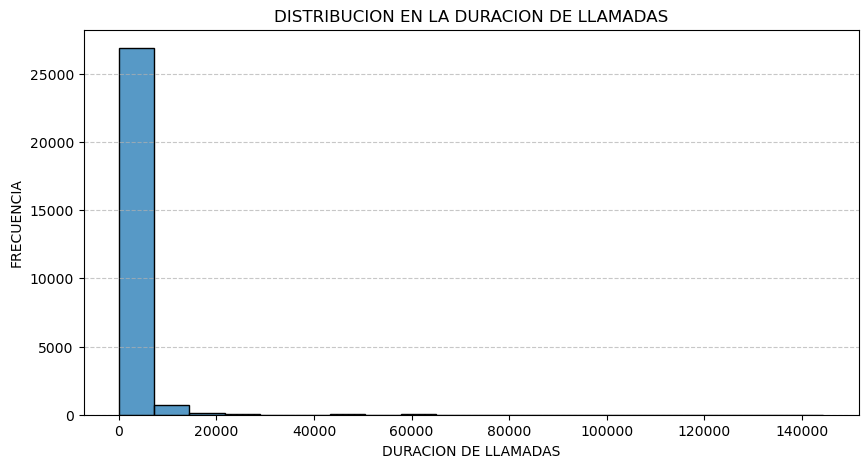

In [11]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df_dataset[df_dataset['call_duration'] > 0], x='call_duration', bins=20, kde=False)
plt.title('DISTRIBUCION EN LA DURACION DE LLAMADAS')
plt.xlabel('DURACION DE LLAMADAS')
plt.ylabel('FRECUENCIA')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

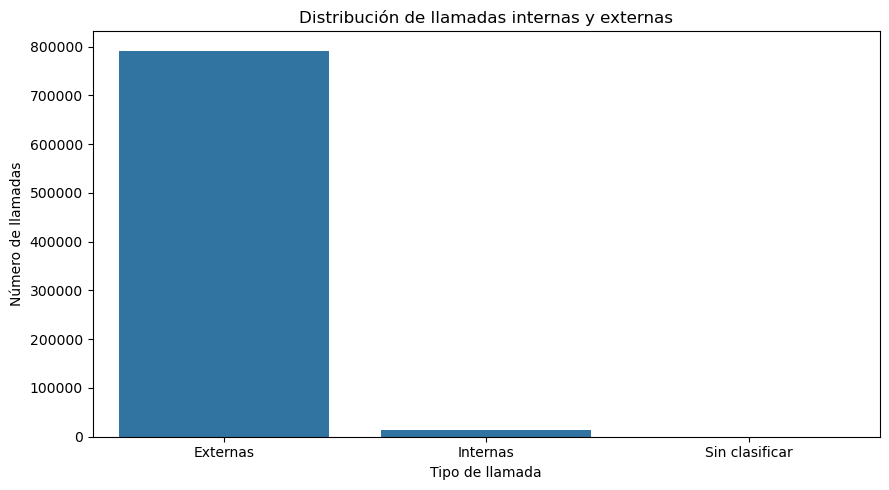

In [12]:
distribucion = (
    df_dataset
    .groupby('internal', dropna=False)['calls_count']
    .sum()
)

distribucion.index = distribucion.index.map({
    False: 'Externas',
    True: 'Internas'
}).fillna('Sin clasificar')

plt.figure(figsize=(9, 5))

sns.barplot(
    x=distribucion.index,
    y=distribucion.values
)

plt.title('Distribución de llamadas internas y externas')
plt.xlabel('Tipo de llamada')
plt.ylabel('Número de llamadas')
plt.tight_layout()
plt.show()

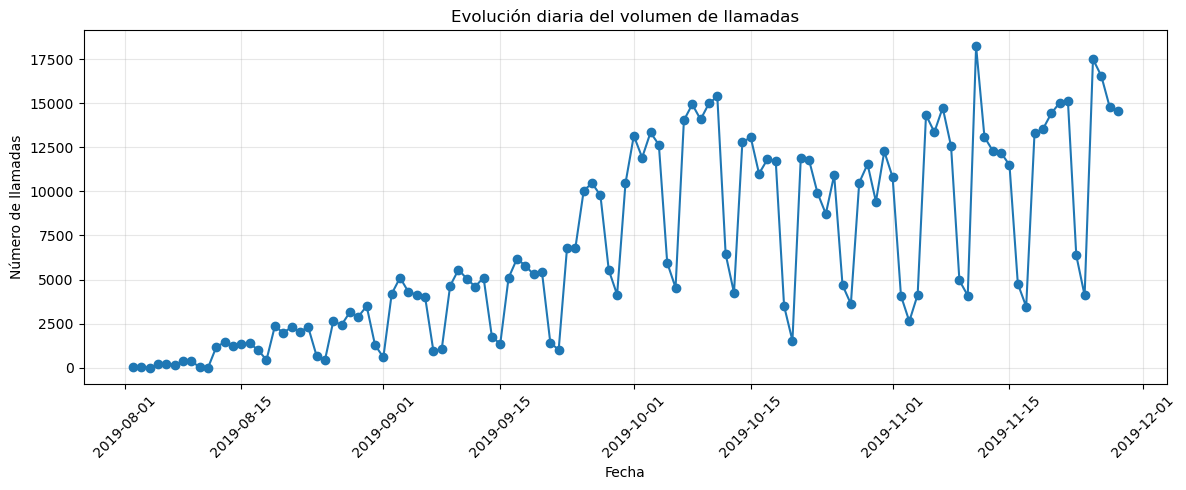

In [13]:
llamadas_diarias = (
    df_dataset
    .groupby(df_dataset['date'].dt.date)['calls_count']
    .sum()
)

plt.figure(figsize=(12, 5))

plt.plot(
    llamadas_diarias.index,
    llamadas_diarias.values,
    marker='o'
)

plt.title('Evolución diaria del volumen de llamadas')
plt.xlabel('Fecha')
plt.ylabel('Número de llamadas')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretación de las visualizaciones

El análisis muestra una distribución desigual de las duraciones registradas, con una concentración importante en valores bajos y presencia de observaciones extremadamente elevadas.

Estos valores requieren una revisión adicional antes de clasificarlos como errores, ya que los registros pueden representar conjuntos de llamadas y no necesariamente comunicaciones individuales.

También se observa que las llamadas externas concentran la mayor parte del tráfico, mientras que las comunicaciones internas representan una proporción considerablemente menor.

Finalmente, el análisis temporal permite identificar variaciones en el volumen diario de llamadas y posibles periodos de mayor actividad operativa.

## 5. Construcción de indicadores de desempeño

In [14]:
if (df_dataset['total_call_duration'] < df_dataset['call_duration']).any():
    raise ValueError('Se encontraron duraciones totales menores a las duraciones de llamada.')

df_dataset['wait_seconds_total'] = (
    df_dataset['total_call_duration'] - df_dataset['call_duration']
)

df_operadores = df_dataset.dropna(subset=['operator_id']).copy()
df_operadores['operator_id'] = df_operadores['operator_id'].astype(int)

df_operadores['incoming_calls'] = np.where(
    df_operadores['direction'] == 'in',
    df_operadores['calls_count'],
    0
)

df_operadores['missed_in_calls'] = np.where(
    (df_operadores['direction'] == 'in') &
    (df_operadores['is_missed_call']),
    df_operadores['calls_count'],
    0
)

df_operadores['incoming_wait_seconds'] = np.where(
    df_operadores['direction'] == 'in',
    df_operadores['wait_seconds_total'],
    0
)

df_operadores['outgoing_calls'] = np.where(
    df_operadores['direction'] == 'out',
    df_operadores['calls_count'],
    0
)

df_operadores['active_day'] = df_operadores['date'].dt.date

rendimiento_operadores = (
    df_operadores
    .groupby('operator_id')
    .agg(
        incoming_calls=('incoming_calls', 'sum'),
        missed_in_calls=('missed_in_calls', 'sum'),
        incoming_wait_seconds=('incoming_wait_seconds', 'sum'),
        outgoing_calls=('outgoing_calls', 'sum'),
        days_active=('active_day', 'nunique')
    )
    .reset_index()
)

rendimiento_operadores['missed_in_rate'] = (
    rendimiento_operadores['missed_in_calls'] /
    rendimiento_operadores['incoming_calls'].replace(0, np.nan)
)

rendimiento_operadores['avg_wait_seconds_per_in_call'] = (
    rendimiento_operadores['incoming_wait_seconds'] /
    rendimiento_operadores['incoming_calls'].replace(0, np.nan)
)

rendimiento_operadores['out_calls_per_active_day'] = (
    rendimiento_operadores['outgoing_calls'] /
    rendimiento_operadores['days_active']
)

min_in_calls = 20

base_evaluable = rendimiento_operadores[
    rendimiento_operadores['incoming_calls'] >= min_in_calls
].copy()

umbral_tasa_perdidas = base_evaluable['missed_in_rate'].quantile(0.90)

umbral_espera = base_evaluable[
    'avg_wait_seconds_per_in_call'
].quantile(0.90)

print('OPERADORES IDENTIFICADOS:', len(rendimiento_operadores))
print('OPERADORES EVALUABLES:', len(base_evaluable))
print(f'UMBRAL DE LLAMADAS PERDIDAS: {umbral_tasa_perdidas:.2%}')
print(f'UMBRAL DE ESPERA: {umbral_espera:.2f} segundos')

display(rendimiento_operadores.head())

OPERADORES IDENTIFICADOS: 1092
OPERADORES EVALUABLES: 356
UMBRAL DE LLAMADAS PERDIDAS: 3.70%
UMBRAL DE ESPERA: 28.82 segundos


,operator_id,incoming_calls,missed_in_calls,incoming_wait_seconds,outgoing_calls,days_active,missed_in_rate,avg_wait_seconds_per_in_call,out_calls_per_active_day
0,879896,58,0,574,872,50,0.0,9.896552,17.440000
1,879898,104,0,1680,7209,84,0.0,16.153846,85.821429
2,880020,7,0,54,38,14,0.0,7.714286,2.714286
3,880022,8,0,112,189,42,0.0,14.000000,4.500000
4,880026,24,0,143,2208,77,0.0,5.958333,28.675325



### Definición de indicadores y criterios de evaluación

Se construyeron indicadores de desempeño por operador considerando el volumen de llamadas entrantes, la proporción de llamadas perdidas y los tiempos de espera.

Para realizar comparaciones más consistentes, se utilizaron tasas y promedios por llamada en lugar de depender exclusivamente de cantidades absolutas.

Se estableció un mínimo exploratorio de 20 llamadas entrantes por operador. Los operadores que no alcanzan este volumen se consideran no evaluables bajo este criterio, debido a que sus métricas pueden presentar una mayor variabilidad.

Para identificar posibles casos de atención prioritaria se utilizaron los percentiles 90 de la tasa de llamadas perdidas y del tiempo promedio de espera entre los operadores evaluables.

Estos límites permiten detectar valores relativamente elevados dentro de la muestra, pero no constituyen estándares operativos definitivos.

El volumen de llamadas salientes se conserva como indicador complementario, ya que no se conocen las metas individuales ni las responsabilidades específicas de cada operador.

Finalmente, una parte considerable de las llamadas entrantes perdidas no tiene operador asignado. Por ello, resulta necesario analizar también los procesos de enrutamiento y asignación antes de atribuir estos resultados al desempeño individual.


## 6. Clasificación y segmentación de operadores

In [15]:

rendimiento_operadores['segmento'] = 'Muestra insuficiente'

rendimiento_operadores.loc[
    rendimiento_operadores['incoming_calls'] == 0,
    'segmento'
] = 'Sin llamadas entrantes'

mascara_evaluable = (
    rendimiento_operadores['incoming_calls'] >= min_in_calls
)

bandera_perdidas = (
    rendimiento_operadores['missed_in_rate'] > umbral_tasa_perdidas
)

bandera_espera = (
    rendimiento_operadores['avg_wait_seconds_per_in_call'] > umbral_espera
)

rendimiento_operadores.loc[
    mascara_evaluable,
    'segmento'
] = 'Dentro de parámetros'

rendimiento_operadores.loc[
    mascara_evaluable & (bandera_perdidas | bandera_espera),
    'segmento'
] = 'Requiere atención'

conteo_segmentacion = rendimiento_operadores['segmento'].value_counts()

print('CLASIFICACIÓN DE OPERADORES')
display(conteo_segmentacion)

print('\nPORCENTAJE SOBRE TODOS LOS OPERADORES IDENTIFICADOS')
display(
    (rendimiento_operadores['segmento']
     .value_counts(normalize=True) * 100).round(2)
)

print('\nOPERADORES QUE REQUIEREN ATENCIÓN')
display(
    rendimiento_operadores[
        rendimiento_operadores['segmento'] == 'Requiere atención'
    ].sort_values(
        'missed_in_rate',
        ascending=False
    ).head(10)
)


CLASIFICACIÓN DE OPERADORES


segmento
Muestra insuficiente      398
Sin llamadas entrantes    338
Dentro de parámetros      294
Requiere atención          62
Name: count, dtype: int64


PORCENTAJE SOBRE TODOS LOS OPERADORES IDENTIFICADOS


segmento
Muestra insuficiente      36.45
Sin llamadas entrantes    30.95
Dentro de parámetros      26.92
Requiere atención          5.68
Name: proportion, dtype: float64


OPERADORES QUE REQUIEREN ATENCIÓN


,operator_id,incoming_calls,missed_in_calls,incoming_wait_seconds,outgoing_calls,days_active,missed_in_rate,avg_wait_seconds_per_in_call,out_calls_per_active_day,segmento
282,906412,26,7,400,315,30,0.269231,15.384615,10.500000,Requiere atención
246,905300,25,6,552,0,15,0.240000,22.080000,0.000000,Requiere atención
675,937368,22,4,531,10,12,0.181818,24.136364,0.833333,Requiere atención
823,944226,180,30,7679,109,36,0.166667,42.661111,3.027778,Requiere atención
263,905862,102,15,1165,1,34,0.147059,11.421569,0.029412,Requiere atención
1021,959312,56,7,418,145,12,0.125000,7.464286,12.083333,Requiere atención
557,926872,24,3,19,7,13,0.125000,0.791667,0.538462,Requiere atención
22,884408,35,4,924,25,12,0.114286,26.400000,2.083333,Requiere atención
349,911102,27,3,822,0,18,0.111111,30.444444,0.000000,Requiere atención
819,944216,235,24,8368,133,36,0.102128,35.608511,3.694444,Requiere atención



### Interpretación de la segmentación

Se identificaron 1,092 operadores con actividad registrada en el conjunto de datos.

De ellos, 356 cuentan con al menos 20 llamadas entrantes y cumplen el criterio mínimo establecido para esta evaluación exploratoria.

Entre los operadores evaluables:

- **62 operadores (17.42%)** presentan al menos una señal de atención prioritaria.
- **294 operadores (82.58%)** se encuentran dentro de los parámetros exploratorios definidos.

Adicionalmente, 398 operadores presentan una muestra insuficiente de llamadas entrantes y 338 no registran llamadas entrantes.

Estas categorías no deben interpretarse como operadores necesariamente deficientes o eficientes, ya que no conocemos sus funciones específicas, sus objetivos individuales ni todos los factores que afectan su actividad.

Los resultados permiten identificar casos que podrían beneficiarse de una revisión operativa más detallada.

También se detectó que aproximadamente el 99.1% de las llamadas entrantes marcadas como perdidas no tiene un operador identificado. Este hallazgo sugiere que, además de revisar el desempeño individual, es importante investigar el proceso de asignación y enrutamiento de llamadas.


## 7. Análisis de sensibilidad de la clasificación

In [16]:

resultados_sensibilidad = []

for minimo in [10, 20, 30]:

    muestra = rendimiento_operadores[
        rendimiento_operadores['incoming_calls'] >= minimo
    ].copy()

    tasa_limite = muestra['missed_in_rate'].quantile(0.90)

    espera_limite = muestra[
        'avg_wait_seconds_per_in_call'
    ].quantile(0.90)

    alertas = (
        (muestra['missed_in_rate'] > tasa_limite) |
        (muestra['avg_wait_seconds_per_in_call'] > espera_limite)
    )

    resultados_sensibilidad.append({
        'Mínimo de llamadas': minimo,
        'Operadores evaluables': len(muestra),
        'Operadores con alerta': int(alertas.sum()),
        'Porcentaje con alerta': round(alertas.mean() * 100, 2),
        'Umbral pérdida (%)': round(tasa_limite * 100, 2),
        'Umbral espera (s)': round(espera_limite, 2)
    })

df_sensibilidad = pd.DataFrame(resultados_sensibilidad)

display(df_sensibilidad)


,Mínimo de llamadas,Operadores evaluables,Operadores con alerta,Porcentaje con alerta,Umbral pérdida (%),Umbral espera (s)
0,10,446,80,17.94,4.76,29.43
1,20,356,62,17.42,3.70,28.82
2,30,296,53,17.91,2.98,27.52



### Interpretación del análisis de sensibilidad

Para evaluar la estabilidad descriptiva de la clasificación, se probaron tres tamaños mínimos de actividad: 10, 20 y 30 llamadas entrantes por operador.

Los resultados muestran que el número de operadores evaluables disminuye conforme aumenta el mínimo requerido.

Sin embargo, la proporción de operadores con al menos una alerta se mantiene relativamente estable, entre 17.42% y 17.94%, utilizando umbrales recalculados para cada muestra.

Esto sugiere que la proporción general de alertas no cambia drásticamente con estos tres criterios de volumen mínimo.

No obstante, esta estabilidad agregada no garantiza que siempre sean los mismos operadores los identificados. Los resultados deben interpretarse como señales exploratorias que requieren validación con información adicional sobre funciones, metas y condiciones de trabajo.

Este análisis es descriptivo y no demuestra que los operadores identificados sean objetivamente ineficaces.


## 8. Conclusiones y recomendaciones de negocio

### Principales hallazgos

El análisis permitió estudiar el comportamiento de las llamadas de un servicio de telefonía virtual e identificar posibles oportunidades de mejora en su operación.

Después de eliminar registros duplicados exactos, se conservaron 49,002 registros para analizar el tráfico general.

Se identificaron 1,092 operadores, de los cuales 356 cumplieron el mínimo exploratorio de 20 llamadas entrantes establecido para la evaluación individual.

De estos operadores evaluables, 62 (17.42%) presentaron al menos una alerta relacionada con la tasa de llamadas entrantes perdidas o el tiempo promedio de espera.

Un hallazgo especialmente relevante fue que aproximadamente el 99.1% de las llamadas entrantes marcadas como perdidas no tenía un operador identificado, lo que limita la posibilidad de atribuirlas al desempeño individual.

### Recomendaciones

**1. Revisar los procesos de asignación de llamadas.**

Investigar por qué una proporción elevada de llamadas entrantes perdidas no tiene operador identificado. Revisar el enrutamiento, la disponibilidad de operadores y los mecanismos de registro.

**2. Dar seguimiento a los operadores con alertas.**

Analizar los casos identificados considerando su carga de trabajo, horarios, responsabilidades y condiciones operativas antes de establecer medidas correctivas.

**3. Implementar indicadores periódicos de desempeño.**

Monitorear la tasa de llamadas entrantes perdidas, el tiempo promedio de espera por llamada y los volúmenes de actividad, utilizando criterios comparables entre operadores.

**4. Establecer metas diferenciadas.**

Distinguir entre operadores enfocados en llamadas entrantes, salientes o ambas funciones. La evaluación debe adaptarse a sus responsabilidades específicas.

### Limitaciones

Los umbrales empleados son exploratorios y se basan en la distribución de los datos disponibles.

No se dispone de información completa sobre horarios, objetivos individuales, causas de llamadas perdidas o procesos de asignación.

La ausencia de identificadores de operador en numerosas llamadas limita la evaluación individual.

Asimismo, la eliminación de registros duplicados exactos supone que estos corresponden a duplicaciones del dataset. Dado que los registros agrupan llamadas, sería conveniente validar esta suposición con información del sistema de origen.

### Conclusión general

El análisis permitió identificar tanto operadores que podrían requerir seguimiento como posibles problemas relacionados con la asignación y gestión de llamadas.

La principal recomendación es combinar el monitoreo de indicadores individuales con una revisión de los procesos operativos del servicio.

De esta manera, la empresa podría tomar decisiones más informadas sin atribuir automáticamente las dificultades del servicio al desempeño de sus operadores.
